In [1]:
from ase.io.trajectory import Trajectory 
from ase.md.langevin import Langevin 
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution 

import numpy as np 
from mace.calculators import mace_mp,mace_off 
from chgnet.model.dynamics import CHGNetCalculator 
from chgnet.model import CHGNet 
from ase import units 

/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


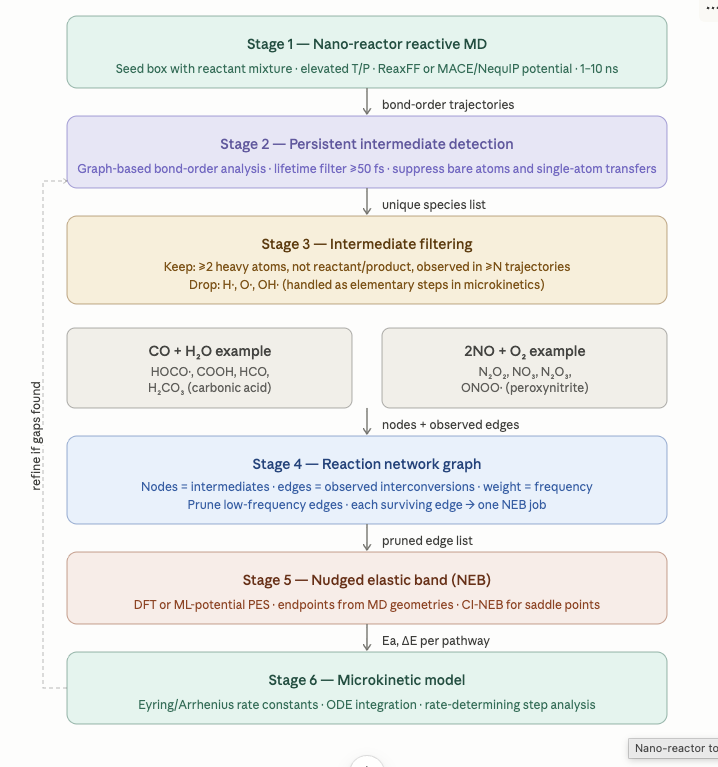

## 1. build the cell (Forward)

In [28]:
from smilesbox.smilesbox import SMILESbox
#smiles = ["N#N","O=O","O=O"]
#smiles = ["N(=O)[O]","N(=O)[O]"]
#smiles = ["C(=O)=O","[HH]"] # forward 
smiles = ["[HH]","[HH]","O=O"]
sm = SMILESbox(
    smiles = smiles * 4,
    box_size=20,
    min_distance=1.0
)
atoms = sm.atoms

In [29]:
calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps



NanoReactor starting
  24 atoms | T=4500 K | NVT
  40000 steps × 0.25 fs = 10.0 ps
  τ_min = 10 fs | BO cutoffs = defaults (0.3)
  Output → reactor_output_reaction_3_forward_chgnet

Running MD...
  [SpeciesTracker] processed 500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 1000 frames, 3 unique formulae seen
  [SpeciesTracker] processed 1500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 2000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 2500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 3000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 3500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 4000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 4500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 5000 frames, 5 unique formulae seen
  [SpeciesTracker] processed 5500 frames, 5 unique formulae seen
  [SpeciesTracker] processed 6000 frames, 7 unique formulae seen
  [SpeciesTracker] proce

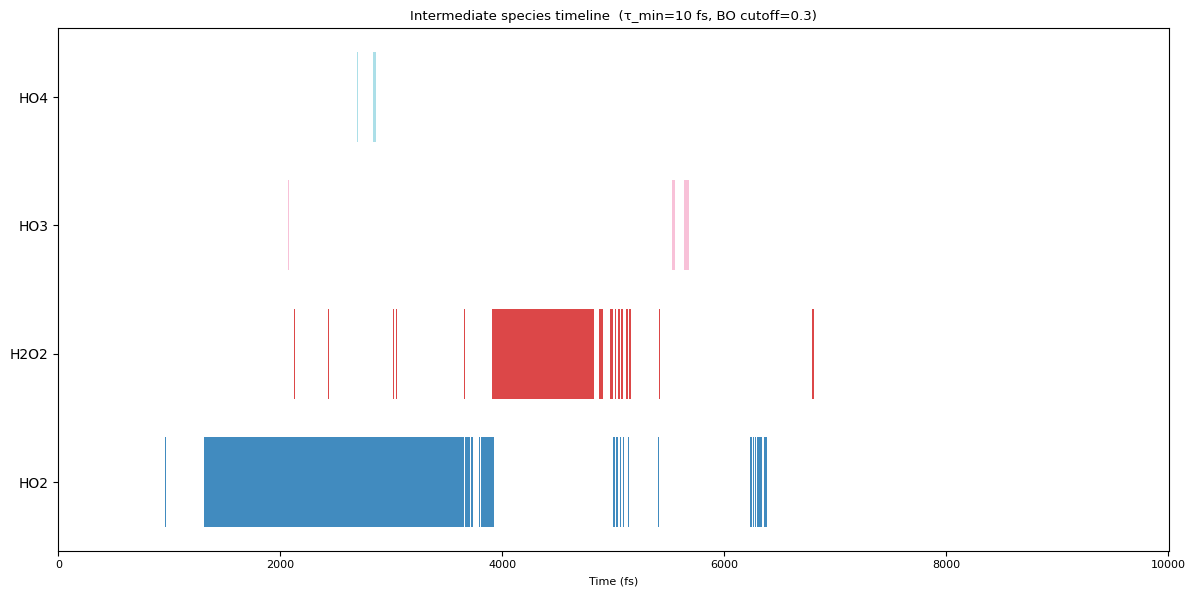

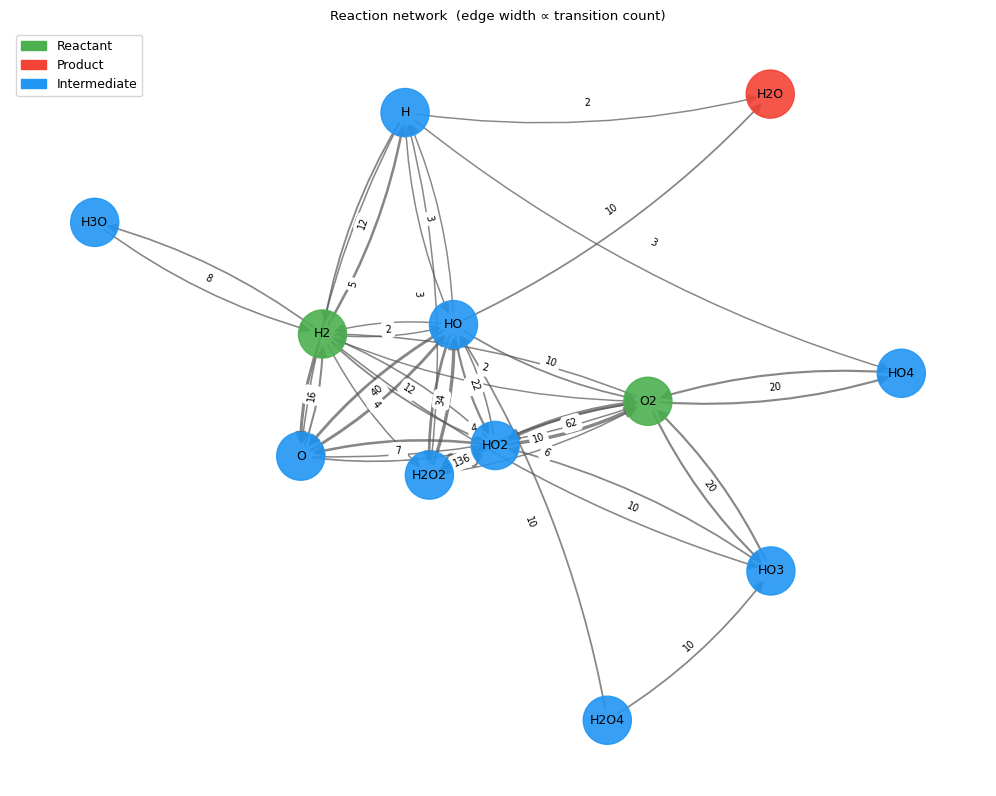

In [30]:
from ase.io import read
from claude_code.nano_reactor import NanoReactor
import warnings 
warnings.simplefilter("ignore")
output_dir = "reactor_output_reaction_3_forward_chgnet"
reactor = NanoReactor(
    atoms        = atoms,
    calculator   = calculator,
    temperature  = 4500,          # K
    total_time_fs= 10000,       # 100 ps
    timestep_fs  = 0.25,
    tau_min_fs   = 10,
    reactants    = {"H2","O2"},
    products     = {"H2O"},
    output_dir   = output_dir,
)

reactor.run()
reactor.report()
reactor.save_summary_csv(f"{output_dir}/results.csv")
reactor.plot()

## 2. Reverse

In [31]:
from smilesbox.smilesbox import SMILESbox
#smiles = ["N#N","O=O","O=O"]
#smiles = ["N(=O)[O]","N(=O)[O]"]
#smiles = ["C(=O)=O","[HH]"] # forward 
#smiles = ["O","[C-]#[O+]"] # reverse 
smiles = ["O","O"]
sm = SMILESbox(
    smiles = smiles * 4,
    box_size=20,
    min_distance=1.0
)
atoms = sm.atoms

In [32]:
calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps


In [ ]:
from ase.io import read
from claude_code.nano_reactor import NanoReactor
import warnings 
warnings.simplefilter("ignore")
output_dir = "reactor_output_reaction_3_reverse_chgnet"
reactor = NanoReactor(
    atoms        = atoms,
    calculator   = calculator,
    temperature  = 4500,          # K
    total_time_fs= 10000,       # 100 ps
    timestep_fs  = 0.25,
    tau_min_fs   = 10,
    reactants    = {"H2O"},
    products     = {"O2","H2"},
    output_dir   = output_dir,
)

reactor.run()
reactor.report()
reactor.save_summary_csv(f"{output_dir}/results.csv")
reactor.plot()


NanoReactor starting
  24 atoms | T=4500 K | NVT
  40000 steps × 0.25 fs = 10.0 ps
  τ_min = 10 fs | BO cutoffs = defaults (0.3)
  Output → reactor_output_reaction_3_reverse_chgnet

Running MD...
  [SpeciesTracker] processed 500 frames, 1 unique formulae seen
  [SpeciesTracker] processed 1000 frames, 3 unique formulae seen
  [SpeciesTracker] processed 1500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 2000 frames, 3 unique formulae seen
  [SpeciesTracker] processed 2500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 3000 frames, 3 unique formulae seen
  [SpeciesTracker] processed 3500 frames, 3 unique formulae seen
  [SpeciesTracker] processed 4000 frames, 3 unique formulae seen
  [SpeciesTracker] processed 4500 frames, 4 unique formulae seen
  [SpeciesTracker] processed 5000 frames, 4 unique formulae seen
  [SpeciesTracker] processed 5500 frames, 4 unique formulae seen
  [SpeciesTracker] processed 6000 frames, 4 unique formulae seen
  [SpeciesTracker] proce